# BD532 Lab 1.2 (Colab): Fine-tune YOLO ตรวจจับอุปกรณ์ความปลอดภัย (PPE)

โน้ตบุ๊กนี้คือ **ฝั่ง training** ของ Lab 1.2 ส่วน **ฝั่ง serving** (FastAPI, หน้าเว็บกล้อง) ทำใน GitHub Codespaces ตามคู่มือ `BD532-Lab-Week1-CV.md`

> ⏱️ **เปิดโน้ตบุ๊กนี้เป็นอันดับแรกของวัน (13:00)** เพราะการ fine-tune ใช้เวลา 15–25 นาที รันส่วน 0–1 เพื่อสั่งเทรนไว้เบื้องหลัง แล้วไปทำ Lab 1.1 (`BD532_Lab1_1_Leaf_Colab.ipynb`) ในแท็บใหม่ กลับมาที่ส่วน 2 หลังพักเบรก

| ส่วน | เวลา | เนื้อหา | ผลลัพธ์ |
|---|---|---|---|
| 0 | 13:00 | เปิด GPU, ติดตั้ง Ultralytics, เชื่อม Google Drive | พร้อมเทรน |
| 1 | 13:05 | **สั่ง fine-tune YOLO PPE ไว้เบื้องหลัง** | งานเทรนวิ่งอยู่ ผลเก็บใน Drive |
| 2 | 15:00 | **Lab 1.2-A:** ตรวจผล fine-tune, เทียบกับโมเดลก่อน fine-tune, export | `bd532_det_artifacts.zip` |

**ทำไมต้องเก็บผลไว้ใน Google Drive:** ระหว่างที่ไปทำ Lab 1.1 ประมาณ 2 ชั่วโมง runtime ของโน้ตบุ๊กนี้อาจถูกตัดเพราะไม่มีการใช้งาน ไฟล์ใน `/content` จะหายไป แต่ไฟล์ใน Drive ยังอยู่ ส่วน 2 จึงทำงานต่อได้แม้ session หลุด

## ส่วน 0: เตรียมเครื่อง (5 นาที)

1. เมนู **Runtime → Change runtime type → Hardware accelerator: T4 GPU** → **Save**
2. รันเซลล์ด้านล่างทีละเซลล์ (`Shift + Enter`)

In [20]:
!nvidia-smi -L    # ต้องเห็น "GPU 0: Tesla T4" ถ้าขึ้น command not found แปลว่ายังไม่ได้เปิด GPU

GPU 0: Tesla T4 (UUID: GPU-be2bd49e-3b01-3d10-47a5-df4ff9f170d6)


In [21]:
# ตรึงเวอร์ชันให้ตรงกับ Codespaces (requirements.txt) — สำคัญมากสำหรับการ deploy
%pip install -q ultralytics==8.4.202
import ultralytics
ultralytics.checks()

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.8/112.6 GB disk)


In [22]:
# เก็บผลการเทรนไว้ใน Google Drive: ถ้า session หลุด ไฟล์โมเดลยังอยู่
from google.colab import drive
drive.mount("/content/drive")

import os
BASE = "/content/drive/MyDrive/bd532"      # โฟลเดอร์งานใน Drive
DATASETS = "/content/datasets"             # ข้อมูลเก็บในเครื่อง Colab (เร็วกว่า Drive)
os.makedirs(BASE, exist_ok=True)
print("ผลการเทรนจะอยู่ที่", BASE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ผลการเทรนจะอยู่ที่ /content/drive/MyDrive/bd532


> ✅ **Checkpoint 0**: เห็น `Tesla T4`, `ultralytics.checks()` แสดง `Ultralytics 8.4.202 ... CUDA:0 (Tesla T4 ...)` และ Drive ถูก mount แล้ว

## ส่วน 1: สั่ง fine-tune YOLO ตรวจจับอุปกรณ์ความปลอดภัย (PPE) ไว้เบื้องหลัง (5 นาที)

**โจทย์ของ Lab 1.2:** ไซต์ก่อสร้างต้องการกล้องที่แจ้งเตือนเมื่อพบคนงาน **ไม่สวมหมวก เสื้อสะท้อนแสง ถุงมือ รองเท้า หรือแว่นนิรภัย**

โมเดล `yolo26n.pt` ที่เทรนมากับ COCO รู้จัก `person` แต่ **ไม่รู้จักหมวกนิรภัย** เราจึง fine-tune ต่อด้วยชุดข้อมูล [Construction-PPE](https://docs.ultralytics.com/datasets/detect/construction-ppe/) (สัญญาอนุญาต CC BY 4.0)

| รายการ | ค่า |
|---|---|
| จำนวนภาพ | train 800 · val 200 (ไฟล์ zip ~618 MB ดาวน์โหลดอัตโนมัติ) |
| คลาส (12) | `helmet` `gloves` `vest` `boots` `goggles` `Person` `forklift` และคลาส "ไม่สวม" `no_helmet` `no_goggle` `no_gloves` `no_boots` `no_vest` |
| ใช้ทำอะไรใน API | คลาส `no_*` คือ **การละเมิด** ที่หน้าเว็บจะแจ้งเตือนเป็นสีแดง |

การเทรน 20 epoch บน T4 ใช้เวลาประมาณ 15–25 นาที เราจึง **สั่งรันเป็น background process** แล้วไปทำ Lab 1.1 ต่อได้ทันที ผลการเทรนเขียนลง Drive ทุก epoch

In [23]:
DET_DATA = "construction-ppe.yaml"      # Ultralytics มี config ของชุดข้อมูลนี้ในตัว และดาวน์โหลดให้เอง
DET_EPOCHS = 20
DET_PROJECT = f"{BASE}/runs/det"
DET_RUN = f"{DET_PROJECT}/ppe"

cmd = (f"nohup yolo detect train model=yolo26n.pt data={DET_DATA} epochs={DET_EPOCHS} "
       f"imgsz=640 batch=16 cache=ram project={DET_PROJECT} name=ppe exist_ok=True "
       f"> /content/det_train.log 2>&1 &")
# กันการสั่งเทรนซ้ำ: ถ้ามีผลใน Drive แล้ว (เช่น กลับมาหลัง session หลุดแล้วกด Run all) จะไม่เริ่มเทรนใหม่ทับ
if os.path.exists(f"{DET_RUN}/weights/last.pt"):
    print("ℹ️ มีผลการเทรนใน Drive แล้ว ไม่สั่งเทรนซ้ำ — รันเซลล์ถัดไปเพื่อดูสถานะ")
else:
    os.system(cmd)
    print("🚀 เริ่ม fine-tune แล้ว — เปิดโน้ตบุ๊ก Lab 1.1 ในแท็บใหม่ได้เลย")
    print("ดูความคืบหน้าด้วยเซลล์ถัดไป หรือ !tail -n 3 /content/det_train.log")

ℹ️ มีผลการเทรนใน Drive แล้ว ไม่สั่งเทรนซ้ำ — รันเซลล์ถัดไปเพื่อดูสถานะ


In [24]:
import pandas as pd

def det_progress():
    csv = f"{DET_RUN}/results.csv"
    if not os.path.exists(csv):
        print("⏳ ยังไม่จบ epoch แรก (กำลังดาวน์โหลดข้อมูลหรือสร้าง cache) — log ล่าสุด:")
        if os.path.exists("/content/det_train.log"):
            os.system("tail -c 800 /content/det_train.log | tr '\\r' '\\n' | grep -v '^\\s*$' | tail -3")
        return None
    df = pd.read_csv(csv)
    df.columns = df.columns.str.strip()
    print(f"เทรนแล้ว {len(df)}/{DET_EPOCHS} epoch")
    return df[["epoch", "train/box_loss", "train/cls_loss", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].tail(5)

det_progress()

เทรนแล้ว 20/20 epoch


,epoch,train/box_loss,train/cls_loss,metrics/mAP50(B),metrics/mAP50-95(B)
15,16,1.23103,0.85721,0.71331,0.50605
16,17,1.20650,0.83614,0.71473,0.50749
17,18,1.20374,0.81971,0.71797,0.51079
18,19,1.20161,0.82742,0.71793,0.51233
19,20,1.19167,0.81248,0.71890,0.51180


> ✅ **Checkpoint 1**: เซลล์ด้านบนแสดง log ว่ากำลังดาวน์โหลด/เทรน หรือแสดงตาราง epoch (รันซ้ำได้เรื่อย ๆ เพื่อดูความคืบหน้า)
>
> ⚠️ **เปิดแท็บนี้ทิ้งไว้** อย่ากด Disconnect หรือ Delete runtime อย่างน้อยจนกว่าการเทรนจะเสร็จ (ประมาณ 25 นาที)

➡️ **เปิดโน้ตบุ๊ก Lab 1.1 (`BD532_Lab1_1_Leaf_Colab.ipynb`) ในแท็บใหม่** แล้วกลับมาที่ส่วน 2 ของโน้ตบุ๊กนี้หลังพักเบรก (15:00)

## ส่วน 2 (Lab 1.2-A): ตรวจผล fine-tune YOLO และ export (15 นาที)

> 🔌 **ถ้า session หลุดระหว่างที่ไปทำ Lab 1.1** (เห็น `NameError` หรือปุ่ม Reconnect): กด **Runtime → Run all** ได้เลย เซลล์สั่งเทรนในส่วน 1 จะเห็นผลใน Drive และไม่เทรนซ้ำ ส่วน 2.2 จะดาวน์โหลดชุดข้อมูลใหม่ให้เองประมาณ 1–3 นาที

### 2.1 การเทรนเสร็จหรือยัง

In [25]:
import glob
import matplotlib.pyplot as plt
from IPython.display import Image as Show, display
from ultralytics import YOLO

det_progress()

เทรนแล้ว 20/20 epoch


,epoch,train/box_loss,train/cls_loss,metrics/mAP50(B),metrics/mAP50-95(B)
15,16,1.23103,0.85721,0.71331,0.50605
16,17,1.20650,0.83614,0.71473,0.50749
17,18,1.20374,0.81971,0.71797,0.51079
18,19,1.20161,0.82742,0.71793,0.51233
19,20,1.19167,0.81248,0.71890,0.51180


- ถ้าเห็น `เทรนแล้ว 20/20 epoch` → ทำต่อได้เลย
- ถ้ายังไม่ครบ → ใช้ `best.pt` ที่มีอยู่ไปก่อนได้ (Ultralytics บันทึกโมเดลที่ดีที่สุด **ทุก epoch**) แล้ว export ใหม่ภายหลัง
- ถ้า session หลุดและไม่มีไฟล์ใน Drive → ใช้ไฟล์ `bd532_det_artifacts.zip` ที่ผู้สอนแจก

### 2.2 อ่านผลการเทรน

In [26]:
print(det_progress())
print("\n--- ไฟล์ใน Drive ---")
!ls -la {DET_RUN} {DET_RUN}/weights 2>&1 | head -30
print("\n--- log ล่าสุด ---")
!tail -c 1500 /content/det_train.log | tr '\r' '\n' | grep -v '^\s*$' | tail -12
print("\n--- งานเทรนยังรันอยู่ไหม ---")
!pgrep -af "yolo detect train" || echo "❌ ไม่มีงานเทรนรันอยู่"

เทรนแล้ว 20/20 epoch
    epoch  train/box_loss  train/cls_loss  metrics/mAP50(B)  \
15     16         1.23103         0.85721           0.71331   
16     17         1.20650         0.83614           0.71473   
17     18         1.20374         0.81971           0.71797   
18     19         1.20161         0.82742           0.71793   
19     20         1.19167         0.81248           0.71890   

    metrics/mAP50-95(B)  
15              0.50605  
16              0.50749  
17              0.51079  
18              0.51233  
19              0.51180  

--- ไฟล์ใน Drive ---
/content/drive/MyDrive/bd532/runs/det/ppe:
total 10067
drwx------ 3 root root   4096 Nov 14 09:01 .
drwx------ 3 root root   4096 Nov 14 08:55 ..
-rw------- 1 root root   1683 Nov 14 08:55 args.yaml
-rw------- 1 root root 423204 Nov 14 09:01 BoxF1_curve.png
-rw------- 1 root root 319939 Nov 14 09:01 BoxP_curve.png
-rw------- 1 root root 306663 Nov 14 09:01 BoxPR_curve.png
-rw------- 1 root root 365006 Nov 14 09:01 BoxR

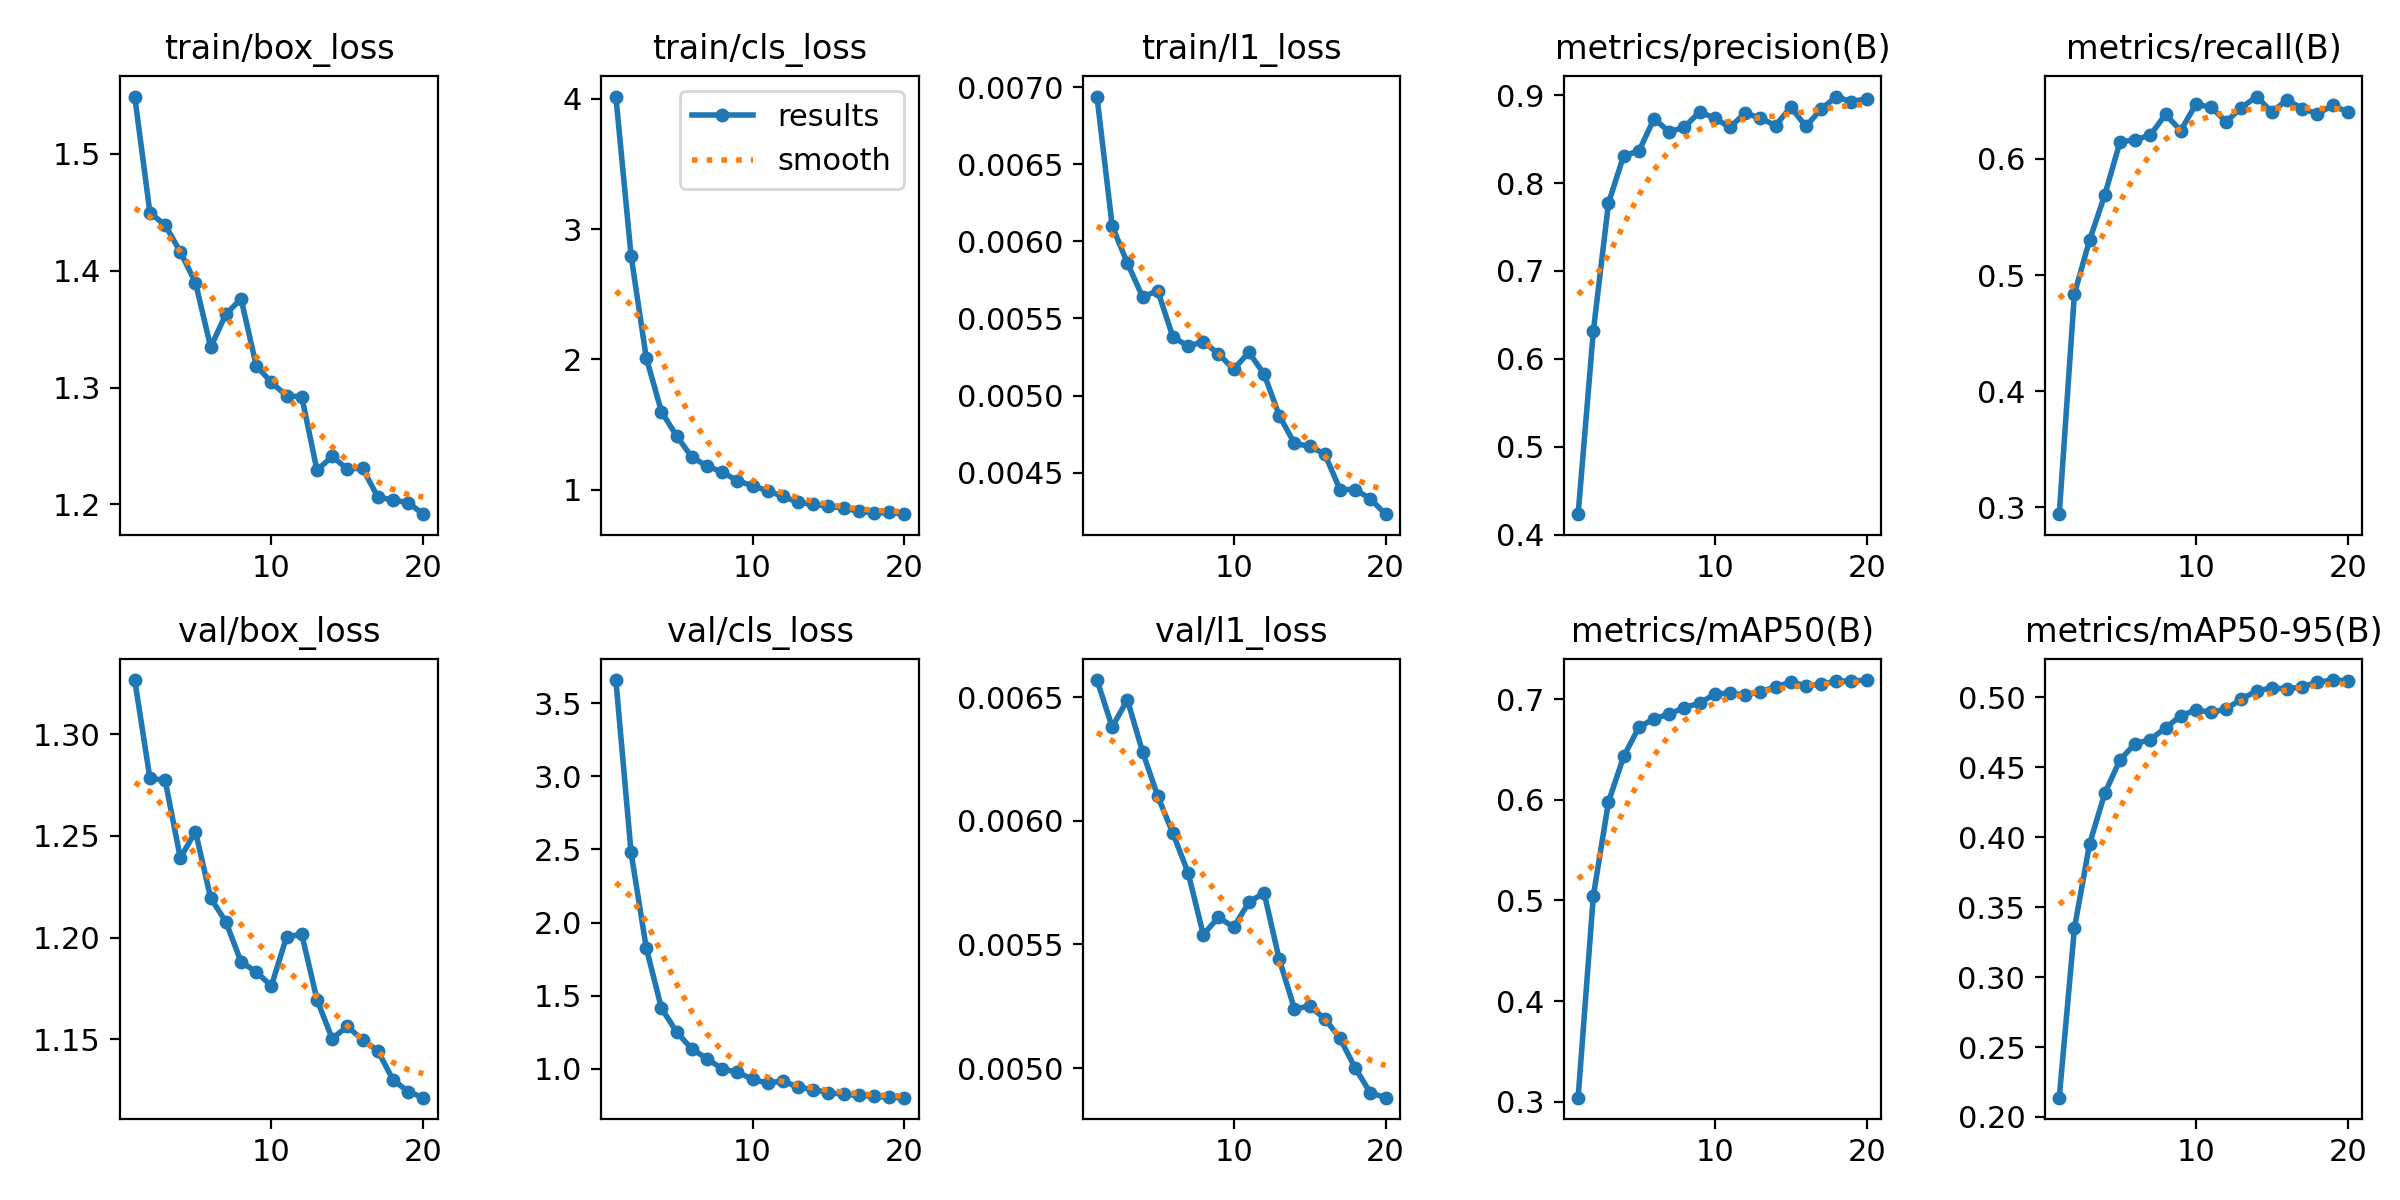

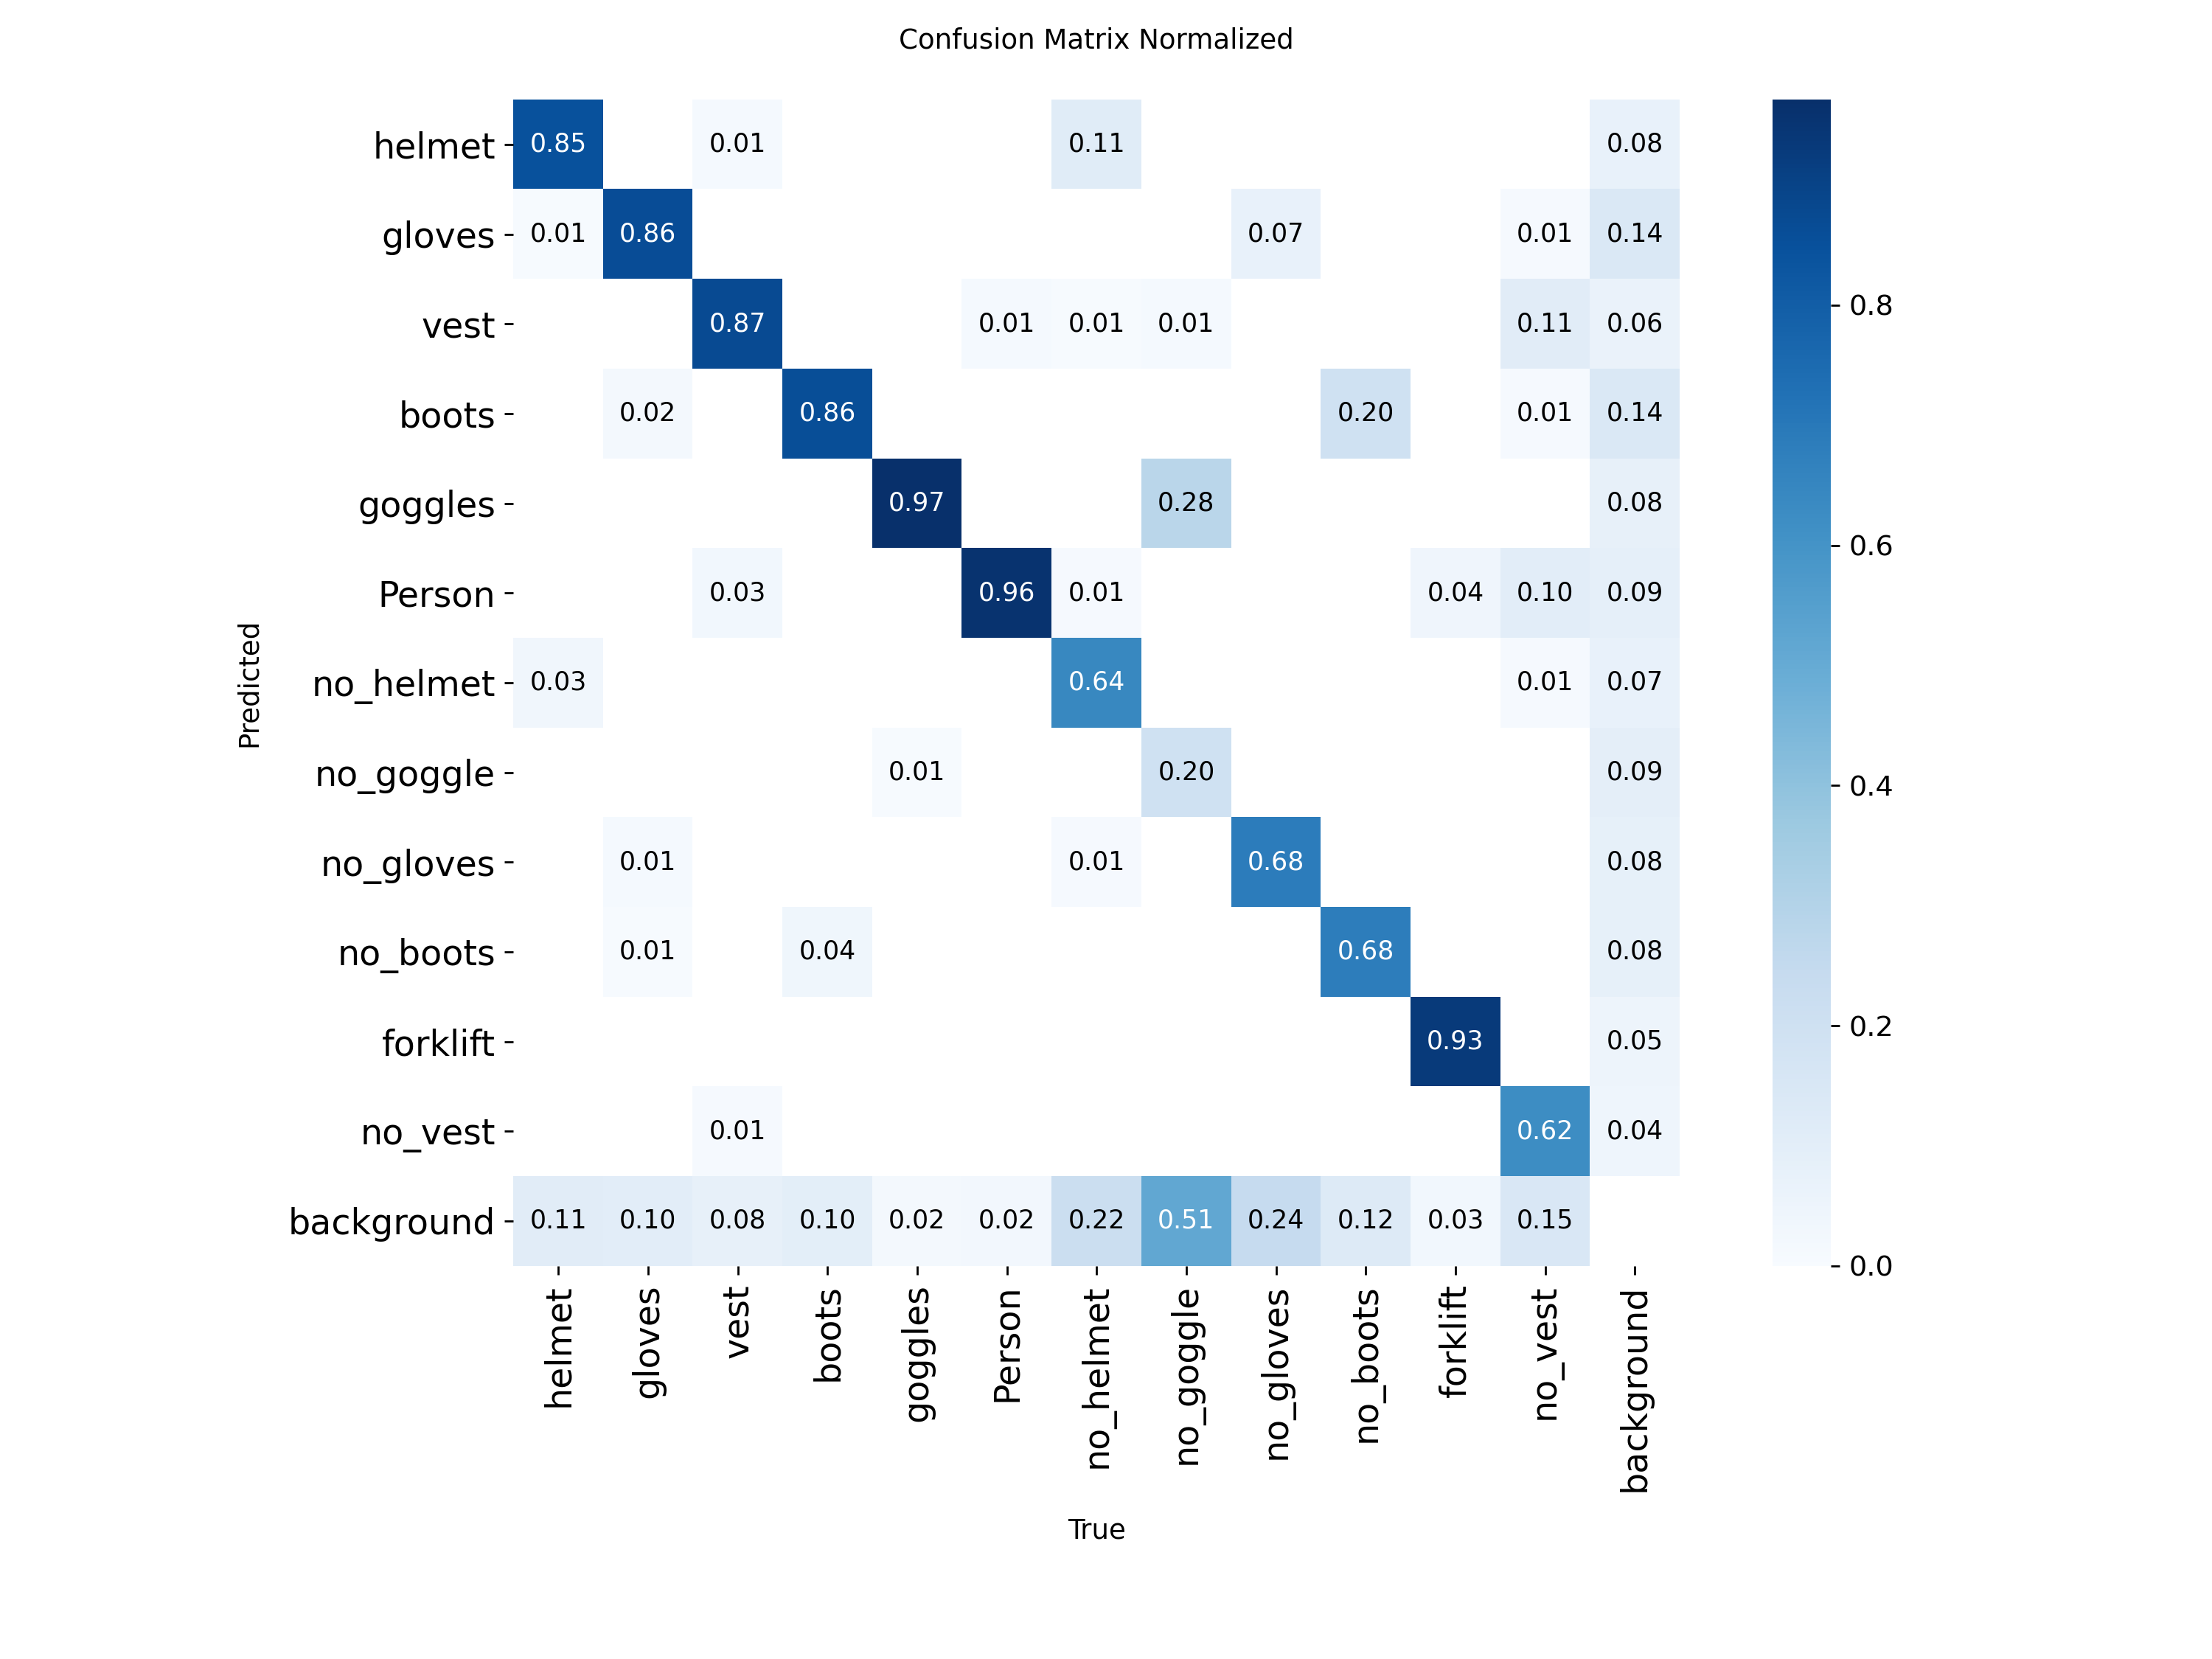

In [27]:
display(Show(f"{DET_RUN}/results.png", width=900))
display(Show(f"{DET_RUN}/confusion_matrix_normalized.png", width=620))

In [28]:
best = YOLO(f"{DET_RUN}/weights/best.pt")
m = best.val(data=DET_DATA, imgsz=640, verbose=False, plots=False)
per_class = pd.DataFrame({"class": [best.names[i] for i in range(len(best.names))],
                          "mAP50-95": m.box.maps.round(3)}).sort_values("mAP50-95")
print(f"mAP50 = {m.box.map50:.3f} · mAP50-95 = {m.box.map:.3f}")
per_class

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,392,408 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4675.3±984.0 MB/s, size: 595.7 KB)
val: Scanning /content/datasets/construction-ppe/labels/val.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 55.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 1.4it/s 9.0s
                   all        200       2961      0.901      0.636      0.718      0.513
Speed: 2.0ms preprocess, 4.6ms inference, 0.0ms loss, 4.5ms postprocess per image
mAP50 = 0.718 · mAP50-95 = 0.513


,class,mAP50-95
7,no_goggle,0.022
6,no_helmet,0.376
8,no_gloves,0.376
11,no_vest,0.467
3,boots,0.554
4,goggles,0.560
9,no_boots,0.562
1,gloves,0.582
10,forklift,0.586
0,helmet,0.618


**คำถามชวนคิด:** คลาสใดได้ mAP ต่ำที่สุด? ถ้าระบบแจ้งเตือนอาศัยคลาส `no_helmet` แต่คลาสนี้แม่นยำต่ำ จะเกิดผลอะไรในไซต์ก่อสร้างจริง (false positive / false negative) และควรตั้ง `conf` ใน API สูงหรือต่ำ

### 2.3 ก่อน vs หลัง fine-tune บนภาพเดียวกัน

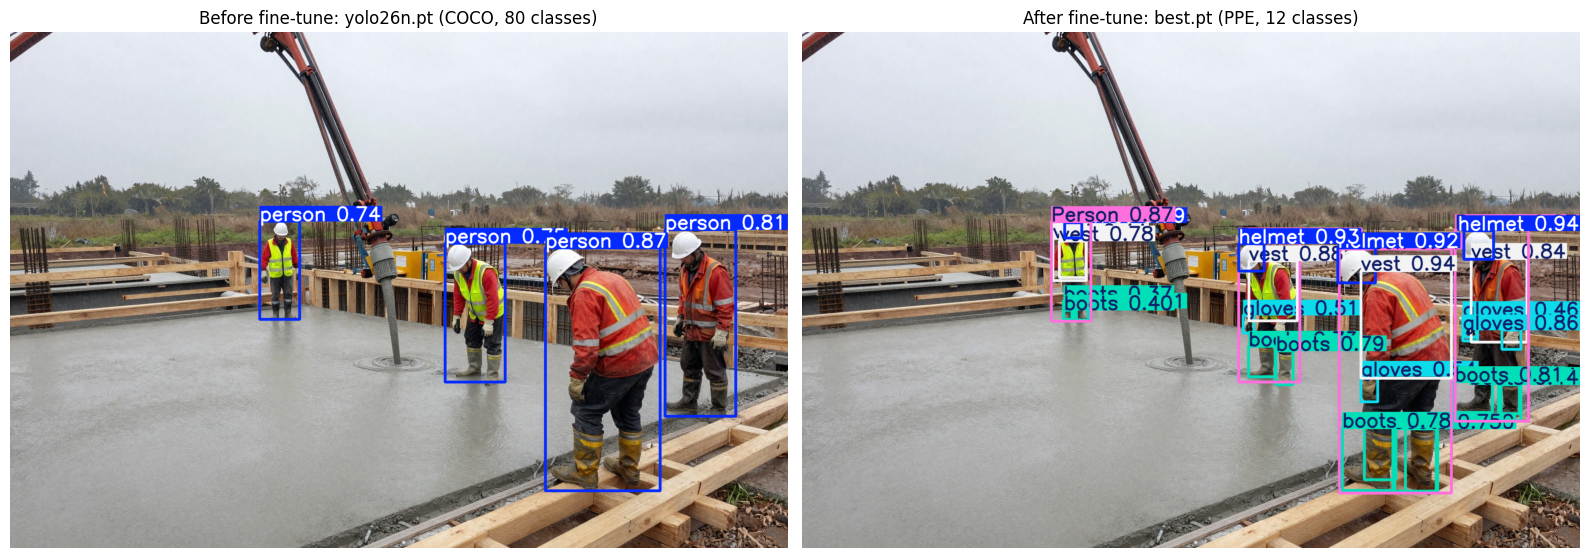

COCO : ['person', 'person', 'person', 'person']
PPE  : ['vest', 'helmet', 'helmet', 'helmet', 'Person', 'vest', 'Person', 'Person', 'Person', 'gloves', 'vest', 'boots', 'boots', 'helmet', 'vest', 'boots', 'boots', 'boots', 'boots', 'gloves', 'gloves', 'gloves', 'vest', 'boots', 'boots', 'boots', 'boots', 'boots', 'boots', 'gloves']


In [29]:
VAL_DIR = f"{DATASETS}/construction-ppe/images/val"
img = sorted(glob.glob(f"{VAL_DIR}/*.jpg"))[3]

coco = YOLO("yolo26n.pt")
r0 = coco.predict(img, imgsz=640, conf=0.25, verbose=False)[0]
r1 = best.predict(img, imgsz=640, conf=0.25, verbose=False)[0]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, r, t in [(axes[0], r0, "Before fine-tune: yolo26n.pt (COCO, 80 classes)"), (axes[1], r1, "After fine-tune: best.pt (PPE, 12 classes)")]:
    ax.imshow(r.plot()[..., ::-1]); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()
print("COCO :", [r0.names[int(c)] for c in r0.boxes.cls])
print("PPE  :", [r1.names[int(c)] for c in r1.boxes.cls])

### 2.4 Export สิ่งที่ API ต้องใช้

สร้าง `bd532_det_artifacts.zip` ที่มี `models/det_best.pt`, `models/det_metadata.json` (มีรายชื่อ `violation_classes`) และรูปตัวอย่าง 8 รูปพร้อมกล่องที่โมเดลตอบใน Colab (`samples/det_expected.json`)

In [30]:
# ===== Export Lab 1.2 artifacts (same code as the Colab cell) =====
import os, json, glob, shutil, datetime
import ultralytics
from PIL import Image
from ultralytics import YOLO

RUN   = DET_RUN
DATA  = DET_DATA
VAL_IMAGES = VAL_DIR
IMGSZ = 640
OUT   = "export_det"

shutil.rmtree(OUT, ignore_errors=True)
os.makedirs(f"{OUT}/models", exist_ok=True)
os.makedirs(f"{OUT}/samples/det", exist_ok=True)
shutil.copy(f"{RUN}/weights/best.pt", f"{OUT}/models/det_best.pt")

model = YOLO(f"{OUT}/models/det_best.pt")
m = model.val(data=DATA, imgsz=IMGSZ, verbose=False, plots=False)

# รูปตัวอย่าง 8 รูป ย่อด้านยาวเหลือ 1280 px (ไฟล์เล็กลง แต่ยังพอให้โมเดลเห็นรายละเอียด)
expected = []
for i, src in enumerate(sorted(glob.glob(f"{VAL_IMAGES}/*.jpg"))[:8]):
    name = f"ppe_{i:02d}.jpg"
    dst = f"{OUT}/samples/det/{name}"
    im = Image.open(src).convert("RGB"); im.thumbnail((1280, 1280)); im.save(dst, quality=90)
    r = model.predict(dst, imgsz=IMGSZ, conf=0.25, verbose=False)[0]
    dets = [{"label": r.names[int(c)], "conf": round(float(p), 4),
             "box": [round(float(v), 1) for v in b]}
            for b, c, p in zip(r.boxes.xyxy.tolist(), r.boxes.cls.tolist(), r.boxes.conf.tolist())]
    expected.append({"file": name, "detections": dets})
json.dump(expected, open(f"{OUT}/samples/det_expected.json", "w"), indent=2, ensure_ascii=False)

meta = {
    "model_version": "det-yolo26n-ppe-v1",
    "task": "detect",
    "base_model": "yolo26n.pt (COCO pretrained)",
    "dataset": "Ultralytics Construction-PPE (12 classes, CC BY 4.0)",
    "imgsz": IMGSZ,
    "names": model.names,
    "violation_classes": [n for n in model.names.values() if n.startswith("no_")],
    "metrics": {"mAP50": round(float(m.box.map50), 4), "mAP50_95": round(float(m.box.map), 4)},
    "ultralytics_version": ultralytics.__version__,
    "exported_at": datetime.datetime.now().isoformat(timespec="seconds"),
}
json.dump(meta, open(f"{OUT}/models/det_metadata.json", "w"), indent=2, ensure_ascii=False)
shutil.make_archive("bd532_det_artifacts", "zip", OUT)
print(json.dumps(meta["metrics"]), "| samples:", len(expected))
print("✅ สร้าง bd532_det_artifacts.zip แล้ว")

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,392,408 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±1.1 ms, read: 3378.7±613.6 MB/s, size: 613.5 KB)
val: Scanning /content/datasets/construction-ppe/labels/val.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 16.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 1.9it/s 6.8s
                   all        200       2961      0.901      0.636      0.718      0.513
Speed: 1.3ms preprocess, 4.2ms inference, 0.0ms loss, 3.5ms postprocess per image
{"mAP50": 0.7183, "mAP50_95": 0.5132} | samples: 8
✅ สร้าง bd532_det_artifacts.zip แล้ว


In [31]:
from google.colab import files
files.download("bd532_det_artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

> ✅ **Checkpoint 2 (ก่อนไป Lab 1.2-B ใน Codespaces)**
> - [ ] บันทึก mAP50 / mAP50-95 ของโมเดล: ______ / ______ และคลาสที่แย่ที่สุด: ______
> - [ ] อธิบายได้ว่าทำไมโมเดล COCO ตรวจหมวกนิรภัยไม่ได้
> - [ ] มีไฟล์ `bd532_det_artifacts.zip` (~8 MB) บนเครื่อง
> - [ ] ดาวน์โหลดโน้ตบุ๊กที่รันแล้ว (**File → Download → Download .ipynb**) ไว้ commit ใน Codespaces

➡️ **ไปทำ Lab 1.2-B ในคู่มือ (Codespaces)**